# Compare visualizations, statistics for small and large crystal datsets

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mdx2.io import loadobj
from mdx2.report.visualization import calc_isoavg, extract_central_slice, unique_slices
from mdx2.report.map_statistics import prepare_table

project_directory = Path("../processing/results")

def subtract_isotropic_part(da, s_iso, intensity_iso):
    s = np.sqrt(da.sx**2 + da.sy**2 + da.sz**2)
    out = da.copy()
    out.data = da.data - np.interp(s, s_iso, intensity_iso)
    return out

def ingest_merged_data(merged_nxs):
    crystal   = loadobj(merged_nxs, 'crystal')
    symmetry  = loadobj(merged_nxs, 'symmetry')
    hkl_table = loadobj(merged_nxs, 'hkl_table')
    s_iso, intensity_iso = calc_isoavg(hkl_table, crystal)
    slices = []
    for slice_index, coord in unique_slices(symmetry):
        intensity = extract_central_slice(hkl_table, symmetry, crystal,
            slice_index=slice_index, slice_coordinate=coord, signal="intensity")
        slices.append({'intensity': intensity,
                       'intensity_subtracted': subtract_isotropic_part(intensity, s_iso, intensity_iso)})
    return {'isotropic': {'s': s_iso, 'intensity': intensity_iso}, 'slices': slices}

bin_width = 0.01
smax = 0.8
nbins = int(smax / bin_width)
bin_edges = np.linspace(0, bin_width*nbins, nbins + 1)

def load_merged_calc_stats(merged_nxs):
    crystal   = loadobj(merged_nxs, 'crystal')
    symmetry  = loadobj(merged_nxs, 'symmetry')
    hkl_table = loadobj(merged_nxs, 'hkl_table')
    df = prepare_table(hkl_table, crystal, symmetry)
    # exclude Bragg points
    df = df[~df["is_reflection"]]
    # compute statistics in each bin
    def rmsavg(x):
        return np.sqrt(np.mean(x * x))
    s_bins = pd.cut(df["s"], bins=bin_edges)
    stats = df.groupby(s_bins, observed=False).agg(
        s=("s", "mean"),
        intensity_iso=("intensity_iso", "mean"),
        intensity_sub_rms=("intensity_sub", rmsavg),
        intensity_error_rms=("intensity_error", rmsavg),
    )
    return stats

## Visualization

In [2]:
# load data

DATASETS = {
    'CHESS 2025-11-05': 'mac1-east-west/chess_20251105/mac1_merge',
    'ALS 2026-04-23': 'mac1-suboptimal/als_20260423/mac1_merge',
}

data = {}

merged_data = {}

for dset_key, dset_root in DATASETS.items():
    merged_nxs = project_directory / dset_root / 'mdx2/merged.nxs'
    merged_data[dset_key] = ingest_merged_data(merged_nxs)

/var/folders/bs/hkvq730j1q7bscf60_pkcmq00000gn/T/ipykernel_90566/1038339528.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/bs/hkvq730j1q7bscf60_pkcmq00000gn/T/ipykernel_90566/1038339528.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


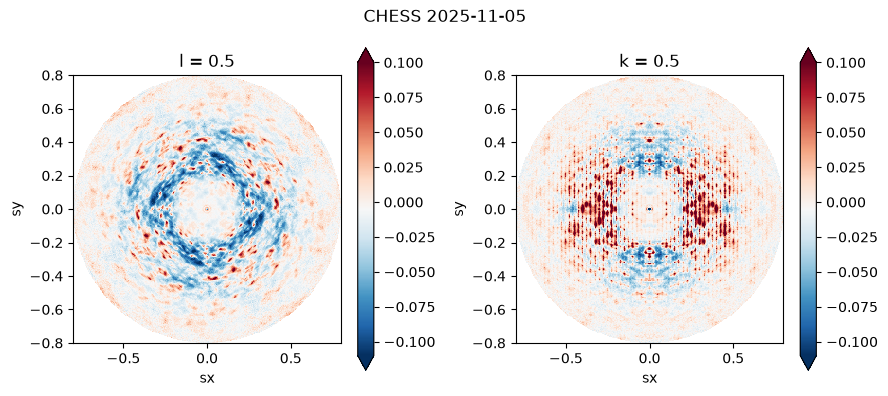

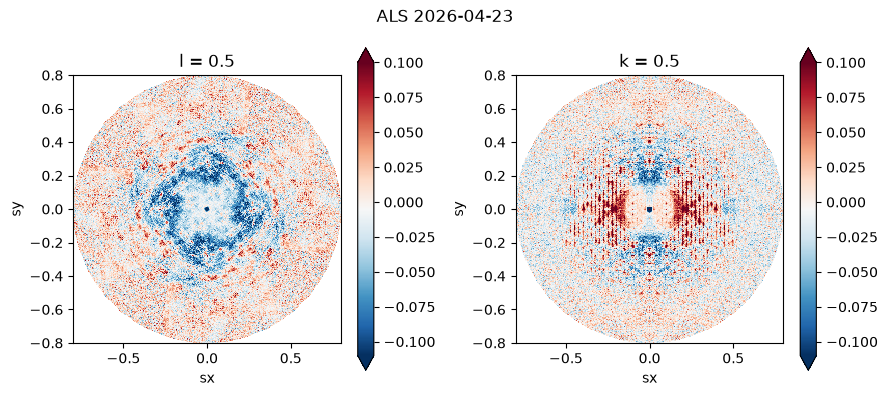

In [3]:
# plot slices

for key in DATASETS:
    fig, ax = plt.subplots(1,2, figsize=(9, 4))
    vals = merged_data[key]
    normval = np.max(vals['isotropic']['intensity'])
    for j, slice_index in enumerate([1,3]):
        slice_data = vals['slices'][slice_index]
        s = np.sqrt(slice_data['intensity'].sx**2 + slice_data['intensity'].sy**2 + slice_data['intensity'].sz**2)
        isub = slice_data['intensity_subtracted'].where(s<0.8,np.nan)/normval
        isub.plot.pcolormesh("sx", "sy", vmin=0.1, vmax=-0.1, cmap = 'RdBu_r', ax=ax[j])
    for a in ax:
        a.set_xlim(-0.8, 0.8)
        a.set_ylim(-0.8, 0.8)
        a.set_aspect('equal', adjustable='box')
    fig.suptitle(key)
    plt.tight_layout()
    fig.show()

In [4]:
# Dump slice data for Figure 6

import xarray as xr

slice_index=1
slices = []
for j, key in enumerate(DATASETS):
    vals = merged_data[key]
    normval = np.max(vals['isotropic']['intensity'])
    sd = vals['slices'][slice_index]['intensity_subtracted']
    sd = sd/normval
    sd = sd.astype('float32')
    sd = sd.rename(key)
    if j > 0:
        sd = sd.drop_vars(('sx','sy','sz'))
    slices.append(sd)
da = xr.merge(slices)
s = np.sqrt(da.sx**2 + da.sy**2 + da.sz**2)
da = da.where(s < 0.8, np.nan)
da = da.where(da['CHESS 2025-11-05'].notnull(),drop=True)
fn = '../figures/source_data/fig6_slices.h5'
print('writing',fn)
da.to_netcdf(fn)


writing ../figures/source_data/fig6_slices.h5


## Intensity vs. s

In [5]:
merged_stats = {}

for dset_key, dset_root in DATASETS.items():
    merged_nxs = project_directory / dset_root / 'mdx2/merged.nxs'
    print('loading',merged_nxs)
    df = load_merged_calc_stats(merged_nxs)
    df['signal_var_est'] = df['intensity_sub_rms']**2 - df['intensity_error_rms']**2
    df.loc[df["signal_var_est"] < 0, "signal_var_est"] = np.nan 
    df.loc[df['s'] < 0.04,'signal_var_est'] = np.nan
    df['irmscorr'] = np.sqrt(df['signal_var_est'])
    merged_stats[dset_key] = df

loading ../processing/results/mac1-east-west/chess_20251105/mac1_merge/mdx2/merged.nxs
loading ../processing/results/mac1-suboptimal/als_20260423/mac1_merge/mdx2/merged.nxs


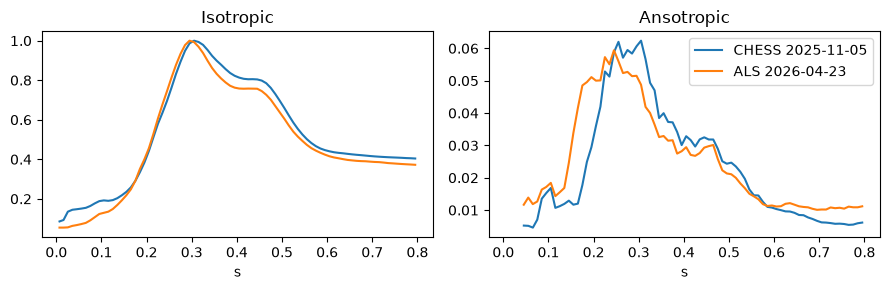

In [6]:
fig, axs = plt.subplots(1,2,figsize=(9,3),sharex=True)
for key in DATASETS:
    df = merged_stats[key].set_index('s')
    normval = df['intensity_iso'].max()
    (df['irmscorr']/normval).plot(ax=axs[1],label=key)
    (df['intensity_iso']/normval).plot(ax=axs[0],label=key)
axs[0].set_title('Isotropic')
axs[1].set_title('Ansotropic')
axs[1].legend()
plt.tight_layout()

## SNR

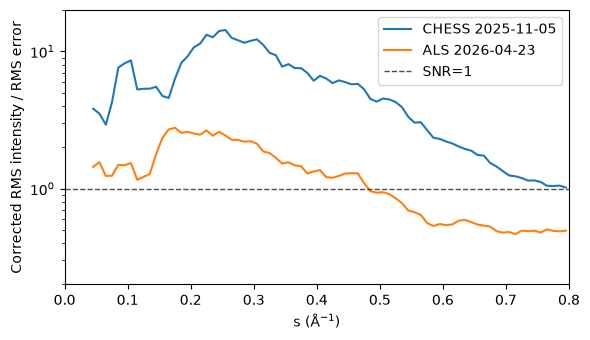

In [7]:
fig, ax = plt.subplots(1,1,figsize=(6,3.5))
for key in DATASETS:
    df = merged_stats[key].set_index('s')
    snr = df['irmscorr'] / df['intensity_error_rms']
    snr.plot(ax=ax,label=key)
ax.axhline(1, color='k', ls='--', lw=1, alpha=0.7, label='SNR=1')
ax.legend()
ax.set_xlim(0, 0.8)
ax.set_ylim(0.2, 20)
ax.set_yscale('log')
ax.set_xlabel("s (Å$^{-1}$)")
ax.set_ylabel('Corrected RMS intensity / RMS error')

plt.tight_layout()

In [8]:
# dump to csv for figure making

dataset_labels = {
    'CHESS 2025-11-05': 'chess_20251105',
    'ALS 2026-04-23': 'als_20260423',
}

for key, label in dataset_labels.items():
    fn = f'../figures/source_data/fig6_iso_aniso_{label}.csv'
    df = merged_stats[key][['s','intensity_iso','irmscorr','intensity_error_rms']]
    df = df.set_index('s')
    df/=df['intensity_iso'].max() # normalize all columns by iso max
    print('Writing',fn)
    df.to_csv(fn)

Writing ../figures/source_data/fig6_iso_aniso_chess_20251105.csv
Writing ../figures/source_data/fig6_iso_aniso_als_20260423.csv
